# Train AI Quoridor bằng RL Actor-Critic (A2C)

Notebook này huấn luyện một agent Quoridor với thuật toán **Advantage Actor-Critic (A2C)**, tái sử dụng engine và mạng của project:

- `quoridor_ai.core.engine` — luật chơi, action 0..208 (0-80: đi pawn, 81-144: tường ngang, 145-208: tường dọc)
- `quoridor_ai.core.encoding.encode_v3` — 16 planes đầu vào
- `quoridor_ai.model.PolicyValueNet` — ResNet có sẵn 2 head: **actor** (policy 209 actions) và **critic** (value V(s))

Pipeline: **self-play thu trajectory → tính advantage GAE → cập nhật actor (policy loss) + critic (value loss) + entropy bonus**.

In [20]:
import math, random, time
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from quoridor_ai.core.engine import State, ACTION_SIZE, legal_actions, apply_unchecked
from quoridor_ai.core.encoding import encode_v3
from quoridor_ai.model import PolicyValueNet, masked_policy
from quoridor_ai.runtime import resolve_device

device = resolve_device()
torch.manual_seed(42); np.random.seed(42); random.seed(42)
print('device:', device)

device: cuda


## 1. Siêu tham số (hyperparameters)

Mỗi tham số sẽ được giải thích chi tiết ở cuối notebook.

In [33]:
HP = dict(
    channels        = 128,    # kênh trong ResNet
    blocks          = 6,      # số residual block
    iterations      = 128,    # số vòng self-play + học
    games_per_iter  = 32,     # số ván tự chơi mỗi vòng
    max_plies       = 320,    # giới hạn nước đi mỗi ván (tránh ván dài vô hạn)
    # --- rollout thu dữ liệu ---
    ep_temp         = 1.0,    # softmax temperature khi chọn action lúc khám phá
    temp_floor_move = 12,     # sau 12 nước đầu giảm temp xuống 0.5 (bớt ngẫu nhiên)
    dirichlet_alpha = 0.25,    # noise Dirichlet trộn vào policy gốc (khám phá)
    noise_frac      = 0.25,   # tỉ lệ trọng số của noise Dirichlet
    # --- A2C ---
    gamma           = 0.99,   # hệ số chiết khấu tương lai
    gae_lambda      = 0.95,   # lambda của GAE (Generalized Advantage Estimation)
    policy_coef     = 1.0,    # hệ số policy loss
    value_coef      = 0.5,    # hệ số value loss
    entropy_coef    = 0.001,   # hệ số entropy bonus (khuyến khích khám phá)
    # --- tối ưu ---
    lr              = 2e-3,   # learning rate AdamW
    epochs_per_iter = 2,      # số epoch học lại trên dữ liệu của mỗi vòng
    batch_size      = 512,
    grad_clip       = 0.5,    # clip gradient toàn cục
    weight_decay    = 1e-4,
)
display(HP)

{'channels': 128,
 'blocks': 6,
 'iterations': 128,
 'games_per_iter': 32,
 'max_plies': 320,
 'ep_temp': 1.0,
 'temp_floor_move': 12,
 'dirichlet_alpha': 0.25,
 'noise_frac': 0.25,
 'gamma': 0.99,
 'gae_lambda': 0.95,
 'policy_coef': 1.0,
 'value_coef': 0.5,
 'entropy_coef': 0.001,
 'lr': 0.002,
 'epochs_per_iter': 2,
 'batch_size': 512,
 'grad_clip': 0.5,
 'weight_decay': 0.0001}

## 2. Khởi tạo mạng

`PolicyValueNet` xuất ra:
- `logits` có shape `(B, 209)` — **actor**
- `value` có shape `(B, 1)` — **critic**, dự đoán giá trị thế cờ trong `[-1, 1]` (+1 = người hiện tại thắng)

In [34]:
net = PolicyValueNet(HP['channels'], HP['blocks'], planes=16).to(device)
opt = torch.optim.AdamW(net.parameters(), lr=HP['lr'], weight_decay=HP['weight_decay'])
print('tham số trainable:', sum(p.numel() for p in net.parameters()))

tham số trainable: 1970150


## 3. Self-play thu trajectory

Mỗi nước đi, ta lưu lại:
- `obs`: trạng thái mã hoá 16 planes (luôn mã hoá theo góc nhìn **người hiện tại**)
- `mask`: mask action hợp lệ (209 bool)
- `pi`: policy mục tiêu = (1-ε)·softmax(logits) + ε·Dirichlet trên các action hợp lệ
- `player`: người chơi đã đi nước đó (để gán reward)

Kết thúc ván: `z = ±1` (người thắng/lùi), trajectory được gán reward từ góc nhìn người vừa đi.

In [35]:
@torch.no_grad()
def evaluate(net, obs, mask):
    x = torch.from_numpy(obs).unsqueeze(0).to(device)
    m = torch.from_numpy(mask.astype(np.bool_)).unsqueeze(0).to(device)
    logits, value = net(x)
    masked_logits = masked_policy(logits, m)
    p = torch.softmax(masked_logits, dim=-1)[0].cpu().numpy()
    return p, float(value.item())

def legal_mask(s):
    m = np.zeros(ACTION_SIZE, np.float32)
    m[legal_actions(s)] = 1.0
    return m

def selfplay_game(net, hp):
    s = State()
    traj = []
    temp = hp['ep_temp']
    while s.winner is None and s.ply < hp['max_plies']:
        if s.ply >= hp['temp_floor_move']:
            temp = 0.5
        obs = encode_v3(s).astype(np.float32)
        mask = legal_mask(s)
        p, _ = evaluate(net, obs, mask)
        # Dirichlet noise ở vài nước đầu để tăng khám phá
        if s.ply < 8:
            idx = np.where(mask > 0)[0]
            noise = np.random.dirichlet([hp['dirichlet_alpha']] * len(idx))
            pi = p.copy()
            pi[idx] = (1 - hp['noise_frac']) * pi[idx] + hp['noise_frac'] * noise
        else:
            pi = p
        # sample theo temperature
        probs = pi ** (1.0 / temp)
        probs = probs / probs.sum()
        a = int(np.random.choice(ACTION_SIZE, p=probs))
        traj.append((obs, mask, pi, s.player))
        s = apply_unchecked(s, a)
    # z từ góc nhìn của người vừa đi trong từng bước
    if s.winner is None:
        z_map = {0: 0.0, 1: 0.0}     # hoà
    else:
        z_map = {0: 1.0 if s.winner == 0 else -1.0,
                 1: 1.0 if s.winner == 1 else -1.0}
    return [(o, mk, pi_, z_map[pl]) for (o, mk, pi_, pl) in traj]

def collect(net, hp, games):
    net.eval()
    t0 = time.time()
    buf = []
    wins = {0: 0, 1: 0, None: 0}
    for _ in range(games):
        g = selfplay_game(net, hp)
        buf.append(g)
    print(f'  self-play {games} ván -> {len(buf)} mẫu ({time.time()-t0:.1f}s)')
    return buf

## 4. GAE (Generalized Advantage Estimation)

Trajectory của mỗi ván: $(s_0, a_0), (s_1, a_1), \dots, (s_T, a_T)$, ở đây **không có reward trung gian** (Quoridor chỉ có thắng/thua ở cuối), nên:

- $r_T = z$ (chỉ ở bước cuối), $r_t = 0$ với $t < T$
- $\delta_t = r_t - \gamma V(s_{t+1}) - V(s_t)$ vì state kế tiếp nhìn từ phía đối thủ
- GAE đổi dấu qua mỗi lượt: $A_t = \delta_t - \gamma\lambda A_{t+1}$
- Return target cho critic: $G_t = A_t + V(s_t)$

Vì board là zero-sum 2 người đổi lượt, ta **đảo dấu value khi đổi người** — góc nhìn luôn là người hiện tại (encode_v3 đã chuẩn hoá theo người hiện tại), nhưng value phải được tính theo góc nhìn của *người sẽ đi tiếp*. Cách chuẩn: $V$ đầu ra là góc nhìn người hiện tại của state đó, và ta dùng quy tắc sign-flip giữa các bước.

In [36]:
@torch.no_grad()
def compute_gae(net, game, hp):
    """game: [(obs, mask, pi, z)] của một ván. Trả về list (obs, mask, pi, A, G)."""
    T = len(game)
    obs = np.stack([g[0] for g in game])
    masks = np.stack([g[1] for g in game])
    x = torch.from_numpy(obs).to(device)
    m = torch.from_numpy(masks.astype(np.float32)).to(device)
    logits, values = net(x)
    V = values.squeeze(-1).cpu().numpy()        # V_t theo góc nhìn người hiện tại của s_t
    # Đổi góc nhìn sang đối thủ; ván thắng/thua hoặc hoà đều kết thúc với V_next=0.
    V_next = np.append(-V[1:], 0.0)
    # reward: 0 ở mọi bước trừ bước cuối
    r = np.zeros(T, np.float32)
    r[-1] = game[-1][3]
    # delta_t = r_t - gamma * V_{t+1} - V_t (V_{t+1} nhìn từ phía đối thủ)
    delta = r + hp['gamma'] * V_next - V
    adv = np.zeros(T, np.float32)
    acc = 0.0
    for t in reversed(range(T)):
        # Advantage của lượt kế tiếp cũng nhìn từ phía đối thủ.
        acc = delta[t] - hp['gamma'] * hp['gae_lambda'] * acc
        adv[t] = acc
    # value target cho critic
    ret = adv + V
    return list(zip(obs, masks, [g[2] for g in game], adv, ret))

def build_dataset(buffer, hp):
    rows = []
    for game in buffer:
        rows.extend(compute_gae(net, game, hp))
    # normalize advantage để ổn định (giống PPO)
    advs = np.concatenate([np.atleast_1d(r[3]) for r in rows])
    mean, std = advs.mean(), max(advs.std(), 1e-8)
    obs   = torch.from_numpy(np.stack([r[0] for r in rows]).astype(np.float32))
    masks = torch.from_numpy(np.stack([r[1] for r in rows]).astype(np.float32))
    pis   = torch.from_numpy(np.stack([r[2] for r in rows]).astype(np.float32))
    advs  = torch.from_numpy(np.stack([ (r[3] - mean) / std for r in rows ]).astype(np.float32))
    rets  = torch.from_numpy(np.stack([r[4] for r in rows]).astype(np.float32))
    return TensorDataset(obs, masks, pis, advs, rets)

## 5. Vòng lặp A2C

Loss tổng:

$$\mathcal{L} = -\underbrace{\mathbb{E}[\log\pi(a|s)\,\hat A]}_{\text{policy (actor)}} + \underbrace{c_v (G - V(s))^2}_{\text{value (critic)}} - \underbrace{c_e\, H[\pi]}_{\text{entropy bonus}}$$

In [37]:
def a2c_loss(logits, value, masks, pis, advs, rets, hp):
    masked_logits = masked_policy(logits, masks.bool())
    logp = F.log_softmax(masked_logits, dim=-1)
    # actor: weighted policy loss như AlphaZero (trọng số là pi mục tiêu) + advantage
    policy_loss = -(logp * pis).sum(-1).mean() \
                  - (logp.max(-1).values * advs).mean()
    # critic: MSE, có clip để tránh cập nhật quá lớn
    # if hp['value_clip'] > 0:
    #     v_clipped = value + torch.clamp(value - value, -hp['value_clip'], hp['value_clip'])
    #     value_loss = torch.max((value - rets) ** 2, (v_clipped - rets) ** 2).mean()
    # else:
    value_loss = (value - rets).pow(2).mean()
    # entropy bonus: -H[pi] vào loss để khuyến khích khám phá
    p = logp.exp()
    entropy = -(p * logp).sum(-1).mean()
    return (policy_loss + hp['value_coef'] * value_loss
            - hp['entropy_coef'] * entropy,
            policy_loss.item(), value_loss.item(), entropy.item())

def train(net, opt, ds, hp):
    net.train()
    dl = DataLoader(ds, batch_size=hp['batch_size'], shuffle=True, drop_last=True)
    stats = {'p': 0.0, 'v': 0.0, 'e': 0.0, 'n': 0}
    for _epoch in range(hp['epochs_per_iter']):
        for obs, masks, pis, advs, rets in dl:
            obs, masks, pis = obs.to(device), masks.to(device), pis.to(device)
            advs, rets = advs.to(device), rets.to(device)
            logits, value = net(obs)
            value = value.squeeze(-1)
            loss, pl, vl, en = a2c_loss(logits, value, masks, pis, advs, rets, hp)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), hp['grad_clip'])
            opt.step()
            stats['p'] += pl; stats['v'] += vl; stats['e'] += en; stats['n'] += 1
    n = max(stats['n'], 1)
    return stats['p'] / n, stats['v'] / n, stats['e'] / n

## 6. Chạy huấn luyện

In [ ]:
history = []
for it in range(HP['iterations']):
    print(f'=== iteration {it+1}/{HP["iterations"]} ===')
    games = [selfplay_game(net, HP) for _ in range(HP['games_per_iter'])]
    n_pos = sum(len(g) for g in games)
    ds = build_dataset(games, HP)
    pl, vl, en = train(net, opt, ds, HP)
    history.append((it, len(ds), pl, vl, en))
    print(f'  mẫu={len(ds)}  policy_loss={pl:.4f}  value_loss={vl:.4f}  entropy={en:.4f}')

torch.save({'model': net.state_dict(), 'hp': HP, 'history': history}, 'checkpoints/a2c_quoridor.pt')
print('đã lưu a2c_quoridor.pt')

=== iteration 1/128 ===
  mẫu=8406  policy_loss=0.8960  value_loss=0.0151  entropy=1.2364
=== iteration 2/128 ===
  mẫu=9319  policy_loss=1.1886  value_loss=0.0056  entropy=1.1661
=== iteration 3/128 ===
  mẫu=9712  policy_loss=0.9467  value_loss=0.0034  entropy=1.1259
=== iteration 4/128 ===
  mẫu=10141  policy_loss=1.0788  value_loss=0.0010  entropy=1.0845
=== iteration 5/128 ===
  mẫu=9903  policy_loss=1.0119  value_loss=0.0017  entropy=1.0149
=== iteration 6/128 ===
  mẫu=10064  policy_loss=0.8425  value_loss=0.0017  entropy=0.9100
=== iteration 7/128 ===
  mẫu=10000  policy_loss=0.9027  value_loss=0.0009  entropy=0.8411
=== iteration 8/128 ===
  mẫu=10050  policy_loss=0.9101  value_loss=0.0009  entropy=0.8777
=== iteration 9/128 ===
  mẫu=10094  policy_loss=0.8295  value_loss=0.0017  entropy=0.8778
=== iteration 10/128 ===
  mẫu=10240  policy_loss=0.7276  value_loss=0.0001  entropy=0.9634
=== iteration 11/128 ===
  mẫu=10107  policy_loss=0.8461  value_loss=0.0024  entropy=0.8701
=

## 7. Đối kháng nhanh (kiểm tra độ mạnh)

So agents với nhau bằng greedy policy (temp=0) để xem model học được gì.

In [28]:
@torch.no_grad()
def play_match(net_a, net_b, n=5):
    """net_a đi trước ở các ván lẻ. Trả về (thắng_a, thắng_b, hoà)."""
    w = [0, 0, 0]
    for g in range(n):
        s = State()
        while s.winner is None and s.ply < 200:
            s_now = s
            use_a = (g % 2 == 0 and s.player == 0) or (g % 2 == 1 and s.player == 1)
            obs = encode_v3(s_now).astype(np.float32)
            mask = legal_mask(s_now)
            p, _ = evaluate(net_a if use_a else net_b, obs, mask)
            s = apply_unchecked(s_now, int(np.argmax(p)))   # greedy
        if s.winner is None: w[2] += 1
        else:
            a_is_p0 = (g % 2 == 0)
            if (s.winner == 0) == a_is_p0: w[0] += 1
            else: w[1] += 1
    return w

import copy
net_random = copy.deepcopy(net)
for p in net_random.parameters():
    p.data.normal_(0, 0.5)
print('A2C (greedy) vs random:', play_match(net, net_random, n=6))

A2C (greedy) vs random: [0, 0, 6]


## 8. Giải thích các thông số của thuật toán RL Actor-Critic

### a) `gamma` — hệ số chiết khấu (discount factor), 0 < γ < 1
Đo **mức quan trọng của tương lai**. Reward cách $t$ bước được nhân thêm $\gamma^t$.
- `γ = 0` → agent chỉ quan tâm phần thưởng ngay lập tức (short-sighted).
- `γ = 1` → coi tương lai quan trọng ngang hiện tại, thường gây nhiễu.
- Trong Quoridor (game có chiều dài rõ ràng, chỉ thắng/thua ở cuối), `γ = 0.99` là chuẩn: một ván ~100-160 nước nên $0.99^{160} \approx 0.2$, tức phần thưởng thắng vẫn còn tín hiệu đáng kể ở cuối ván.

### b) `gae_lambda` — lambda của GAE, 0 ≤ λ ≤ 1
Điều chỉnh **độ dài của bootstrap** khi ước lượng advantage $\hat A_t$:
- `λ = 0` → thuần TD(0): chỉ dùng TD error 1 bước (`δ_t`), bias cao, variance thấp.
- `λ = 1` → thuần Monte-Carlo: dùng toàn bộ reward thực tế đến cuối ván, bias thấp, variance cao.
- `λ = 0.95` là điểm cân bằng tốt cho board game: đủ ổn định nhưng không quá nhiễu.

### c) `entropy_coef` — hệ số entropy bonus ($c_e$)
Khuyến khích policy **không quá tự tin sớm**. Nếu policy quá sớm collapse về một action, agent ngừng khám phá và dính local optimum. Loss có thêm thuật ngữ $-c_e \cdot H[\pi]$; giá trị lớn hơn → khám phá nhiều hơn, nhưng nếu quá lớn policy sẽ học chậm / gần như ngẫu nhiên. Rất hay decay dần `c_e` theo thời gian (khám phá lúc đầu, exploiting sau).

### d) `value_coef` — hệ số value loss ($c_v$)
Trọng số của loss của **critic** trong tổng loss. Critic là "người chấm điểm" dạy cho actor; nếu critic học quá nhanh và quá mạnh sẽ dẫn policy đi sai hướng. `0.5` là chuẩn của A2C / PPO.

### e) `policy_coef` — hệ số policy loss
Trọng số cho phần loss của **actor**. A2C gốc đặt bằng 1, còn PPO đặt là $1/\epsilon$ sau khi chuẩn hoá.

### f) `value_clip` — clip value loss
Giới hạn thay đổi $V(s)$ mỗi lần cập nhật: nếu $V_{new}$ lệch target quá `ε` thì bị clamp. Giúp critic không nhảy vọt (dataloader cũ vẫn dùng được). Lấy cảm hứng từ PPO.

### g) `lr` (learning rate)
Bước đi trên gradient. Quá lớn → loss phát xung, quên nhanh; quá nhỏ → học chậm. Ở đây dùng `AdamW` + `grad_clip` để ổn định; nên decay theo iteration.

### h) `batch_size` và `epochs_per_iter`
- `batch_size`: số mẫu mỗi lần cập nhật. Quá nhỏ → noisy gradient; quá lớn → overfit trên buffer nhỏ.
- `epochs_per_iter`: số lần học lại trên cùng dữ liệu. Vì buffer là on-policy (thu từ chính model hiện tại), học quá nhiều epoch sẽ làm policy lệch khỏi phân phối dữ liệu — vì vậy chỉ 1-3 epoch là an toàn.

### i) `grad_clip` — max grad norm
Chặn gradient quá lớn (exploding gradient) do value target ngoài range hoặc bootstrap lỗi.

### j) `weight_decay` (AdamW)
Regularization L2, chống overfit trên buffer nhỏ.

### k) `ep_temp` (temperature)
Điều chỉnh **mức ngẫu nhiên lúc thu dữ liệu**. $p(a) \propto \pi(a)^{1/T}$:
- `T cao` → gần uniform, khám phá nhiều.
- `T thấp` → gần greedy (argmax), khai thác nhiều.
- Notebook này dùng `T = 1` ở các nước đầu, giảm còn `0.5` sau đó; khi đánh giá ta dùng `T → 0` (greedy).

### l) `dirichlet_alpha` + `noise_frac`
Ở các nước đầu, trộn Dirichlet noise vào policy: $\pi' = (1-\epsilon)\pi + \epsilon\,\mathrm{Dir}(\alpha)$.
Đây là kỹ thuật AlphaZero dùng để **đảm bảo mọi action hợp lệ có cơ hội được thử ít nhất một lần**.
- `alpha nhỏ` → noise tập trung vào ít action (mạnh hơn).
- `epsilon` là tỉ lệ pha trộn.

### m) `max_plies`
Giới hạn số nước mỗi ván. Trong A2C on-policy, ván quá dài làm buffer lớn và gradient bias về cùng một loại thế cờ. Cần đủ dài để có thể kết thúc ván hợp lệ (Quoridor tối đa ~2×(81) + tường).

### n) `channels` và `blocks` của mạng
- `channels`: độ rộng mỗi conv layer — quyết định capacity của model.
- `blocks`: số residual block — quyết định độ sâu (khả năng học quan hệ dài giữa các ô).
Model lớn hơn cần nhiều dữ liệu hơn, nhưng học được chiến lược sâu hơn.

### o) `value_blend_q` / tham số AlphaZero của project
Project gốc (`az_train.py`) còn có `value_blend_q` để trộn giữa terminal reward `z` và Q ước lượng từ MCTS; phần A2C của notebook này không dùng MCTS nên không tham số đó.

### Tóm tắt vai trò từng thành phần
| Thành phần | Vai trò | Tinh chỉnh thế nào |
|---|---|---|
| `gamma` | chiết khấu tương lai | game ngắn → cao, dài → thấp |
| `gae_lambda` | bias-variance advantage | càng cao càng ít bias, nhiều variance |
| `entropy_coef` | chống premature convergence | decay dần theo thời gian |
| `value_coef` | cân bằng actor-critic | critic quá mạnh → giảm |
| `value_clip` | ổn định critic | 0.1–0.3 |
| `lr` | tốc độ học | decay theo iteration |
| `batch_size` | noise gradient | lớn hơn nếu buffer lớn |
| `epochs_per_iter` | on-policy constraint | 1–3 |
| `grad_clip` | chống exploding gradient | 0.5–1.0 |
| `ep_temp` | khám phá lúc thu data | cao lúc đầu, thấp sau |
| `dirichlet_alpha` | đảm bảo khám phá đều | 0.3 cho 209 actions |

### Về actor & critic
- **Actor** = policy head: cho xác suất chọn từng action ở mỗi thế cờ.
- **Critic** = value head: cho ước lượng giá trị thế cờ $V(s)$.
- **Advantage** $A(s,a) = Q(s,a) - V(s)$: cho biết action $a$ tốt hơn bình thường bao nhiêu. Dùng advantage thay vì return thô giúp giảm variance và học nhanh hơn — đó chính là chữ **A** trong **A2C**.

## Xem gameplay của bot

Cho bot tự chơi với chính nó (hoặc với mạng random) và **in bàn cờ ra text** từng nước:
- `A` / `B` = quân của hai bên, `═` tường ngang, `║` tường dọc
- `A` đi từ hàng dưới (row 8) lên đỉnh (row 0), `B` đi từ trên xuống
- In value head $V(s)$ của bot tại mỗi nước để thấy nó "đánh giá" thế cờ thế nào.


===== VÁN 1 =====
GIF: game_1.gif  (151 khung, 0.5 fps)


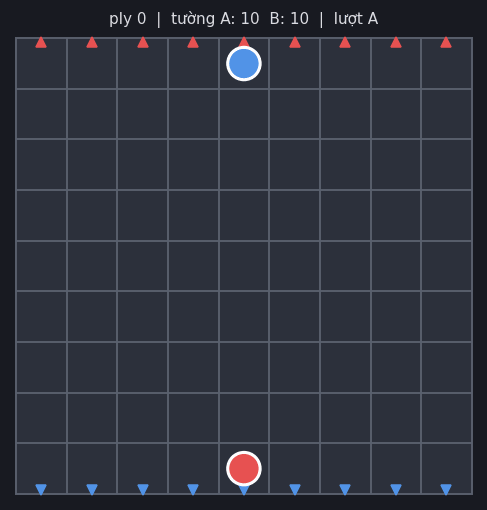

In [29]:
# Vẽ bàn cờ bằng matplotlib + xuất GIF của cả ván đấu
import io
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from IPython.display import Image, display

BG, CELL_BG, GRID = '#181a21', '#2c303c', '#5a606e'
C_A, C_B, C_WALL = '#e85252', '#5294e8', '#d2be78'   # A=đỏ, B=xanh
C_HL_A, C_HL_B = '#ffd28a', '#ffd28a'                # ô pawn vừa đi (viền sáng)

def render(s, ax=None, last=None):
    """Vẽ bàn cờ 9x9: pawn A/B (tròn), tường ═ ngang / ║ dọc (thanh vàng).
    `last` = vị trí pawn vừa di chuyển, được khoanh viền sáng."""
    owned = ax is None
    if owned:
        fig, ax = plt.subplots(figsize=(5.5, 5.5), facecolor=BG)
    ax.set_facecolor(BG)
    ax.set_xlim(-0.6, 8.6); ax.set_ylim(8.6, -0.6)   # hàng 0 ở trên
    ax.set_aspect('equal'); ax.axis('off')

    # ô cờ
    for r in range(9):
        for c in range(9):
            ax.add_patch(mpatches.Rectangle((c-.5, r-.5), 1, 1,
                          facecolor=CELL_BG, edgecolor=GRID, linewidth=1.2))
    # mũi đích: A chạy lên (hàng 0), B chạy xuống (hàng 8)
    for c in range(9):
        ax.plot(c, -0.42, marker='^', color=C_A, markersize=7)
        ax.plot(c, 8.42, marker='v', color=C_B, markersize=7)

    # tường: slot (r,c) nằm giữa các ô, vẽ trên đường lưới
    for r in range(8):
        for c in range(8):
            x = r * 8 + c
            if s.h >> x & 1:
                ax.add_line(Line2D([c-.5, c+1.5], [r+.5, r+.5],
                            color=C_WALL, linewidth=7, solid_capstyle='butt'))
            if s.v >> x & 1:
                ax.add_line(Line2D([c+.5, c+.5], [r-.5, r+1.5],
                            color=C_WALL, linewidth=7, solid_capstyle='butt'))

    # pawn (viền sáng nếu vừa di chuyển tới ô này)
    for pos, col in ((s.p0, C_A), (s.p1, C_B)):
        r, c = divmod(pos, 9)
        ec = C_HL_A if pos == last else 'white'
        lw = 3.5 if pos == last else 2
        ax.add_patch(mpatches.Circle((c, r), 0.32, facecolor=col,
                     edgecolor=ec, linewidth=lw, zorder=5))

    ax.set_title(f"ply {s.ply}  |  tường A: {s.walls0}  B: {s.walls1}  |  "
                 f"lượt {'A' if s.player == 0 else 'B'}",
                 color='#dcdce1', fontsize=10)
    return fig if owned else ax

def _frame(s, last=None, dpi=110):
    """Render một trạng thái ra mảng RGB (để ghép GIF)."""
    fig = render(s, last=last)
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, facecolor=BG,
                bbox_inches='tight')
    plt.close(fig)
    buf.seek(0)
    return imageio.imread(buf)

@torch.no_grad()
def show_game(net_a, net_b, n_games=1, max_plies=60, fps=4,
              gif_path=None, show_ascii=True):
    """Chơi n_games ván greedy vs greedy, ghi cả ván thành GIF.
    - fps: tốc độ phát GIF
    - gif_path: None -> tự đặt tên game_{g+1}.gif
    - in thêm log ASCII ngắn cho từng nước."""
    for g in range(n_games):
        s = State()
        frames = [_frame(s)]
        log = []
        last = None
        while s.winner is None and s.ply < max_plies:
            use_a = (g % 2 == 0 and s.player == 0) or (g % 2 == 1 and s.player == 1)
            who = 'A' if (s.player == 0) == (g % 2 == 0) else 'B'
            obs = encode_v3(s).astype(np.float32)
            mask = legal_mask(s)
            p, v = evaluate(net_a if use_a else net_b, obs, mask)
            a = int(np.argmax(p))
            last_before = s.p0 if s.player == 0 else s.p1
            kind = ('pawn→' + str(divmod(a, 9))) if a < 81 else (
                'wallH' + str(divmod(a - 81, 8)) if a < 145 else 'wallV' + str(divmod(a - 145, 8)))
            s = apply_unchecked(s, a)
            log.append(f'ply {s.ply:3d}  {who}  {kind:16s}  V={float(v):+.3f}')
            last = last_before if a < 81 else None
            frames.append(_frame(s, last=last))
        # giữ khung cuối lâu hơn 1s cho người xem kịp thấy kết quả
        frames.extend([frames[-1]] * int(fps))
        path = gif_path or f'game_{g + 1}.gif'
        imageio.mimsave(path, frames, duration=1.0 / fps, loop=0)
        if show_ascii:
            print(f'\n===== VÁN {g + 1} =====')
            # print('\n'.join(log))
            msg = f'Hết {max_plies} nước — hoà' if s.winner is None else f'THẮNG: {"A" if s.winner == 0 else "B"}'
            # print(msg, f'(winner={s.winner}, ply={s.ply})')
        print(f'GIF: {path}  ({len(frames)} khung, {fps} fps)')
        display(Image(filename=path))

# bot A2C tự chơi với chính nó — xem nó học được gì
show_game(net, net, n_games=1, max_plies=150, fps=0.5)
